In [2]:
# Paso 0 en Colab: sube YaLlego_datos.zip al panel 📁 y ejecuta
!unzip -q -o YaLlego_datos.zip
!pip install -q pandera duckdb openpyxl

In [3]:
!python pipeline.py

--- INICIANDO EXTRACCIÓN ---
El directorio 'YaLlego' ya existe.
Leídos 76232 registros en bruto desde los archivos de pedidos.
Feriados: 12 registros | FUENTE = api

--- INICIANDO TRANSFORMACIÓN ---
Transformación finalizada con éxito.

--- INICIANDO VALIDACIÓN CON PANDERA ---
✔ Validación exitosa. Cero (0) filas rechazadas.

--- INICIANDO CARGA EN DUCKDB ---
✔ Carga de tablas completada con éxito.

================ RESUMEN DE CONTEOS DE TABLAS DUCKDB ================
Tabla: bronce_pedidos                 | Conteo de registros: 76232
Tabla: oro_diario                     | Conteo de registros: 365
Tabla: oro_pedidos                    | Conteo de registros: 75332
Tabla: oro_rendimiento_restaurantes   | Conteo de registros: 40
Tabla: oro_rendimiento_riders         | Conteo de registros: 120
Tabla: plata_clima                    | Conteo de registros: 365
Tabla: plata_feriados                 | Conteo de registros: 12
Tabla: plata_pedidos                  | Conteo de registros: 75332
Tab

In [4]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

con = duckdb.connect("yallego.duckdb")
print("Tablas en yallego.duckdb:")
print(con.execute("SHOW TABLES").df())

print("\nColumnas de oro_diario:")
print(con.execute("DESCRIBE oro_diario").df())

print("\nColumnas de oro_pedidos:")
print(con.execute("DESCRIBE oro_pedidos").df())

Tablas en yallego.duckdb:
                            name
0                 bronce_pedidos
1                     oro_diario
2                    oro_pedidos
3   oro_rendimiento_restaurantes
4         oro_rendimiento_riders
5                    plata_clima
6                 plata_feriados
7                  plata_pedidos
8             plata_restaurantes
9                   plata_riders
10                   plata_zonas
11              rechazos_pedidos

Columnas de oro_diario:
                    column_name column_type null   key default extra
0                         fecha        DATE  YES  None    None  None
1                 total_pedidos      BIGINT  YES  None    None  None
2            pedidos_entregados      BIGINT  YES  None    None  None
3            pedidos_cancelados      BIGINT  YES  None    None  None
4                monto_total_bs      DOUBLE  YES  None    None  None
5                        gmv_bs      DOUBLE  YES  None    None  None
6                   comision_bs      

Top 10 horas más cargadas del año:


,fecha,hora,pedidos_en_hora,riders_en_hora
0,2025-02-22,20,57,47
1,2025-12-24,13,55,44
2,2025-02-22,13,53,45
3,2025-06-21,13,52,43
4,2025-10-22,13,52,41
5,2025-12-31,12,51,43
6,2025-12-20,12,50,39
7,2025-12-13,13,49,41
8,2025-01-18,13,49,41
9,2025-06-21,20,47,41



Ranking de zonas por volumen de pedidos:


,zona_entrega,total_pedidos,pct_demanda,tiempo_prom_min,riders_distintos
0,Centro,10579,14.04,24.3,120
1,Cala Cala,8158,10.83,20.6,120
2,Queru Queru,7541,10.01,20.7,120
3,Sacaba,6618,8.79,38.3,120
4,Sarco,6058,8.04,20.8,120
5,Tupuraya,6047,8.03,21.0,120
6,Tiquipaya,6013,7.98,30.7,120
7,Quillacollo,5310,7.05,39.9,120
8,Muyurina,5291,7.02,21.6,120
9,Pacata,4597,6.10,21.9,120


/tmp/ipykernel_482/4025511728.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_zonas, y="zona_entrega", x="total_pedidos", palette="Blues_r", ax=axes[1])


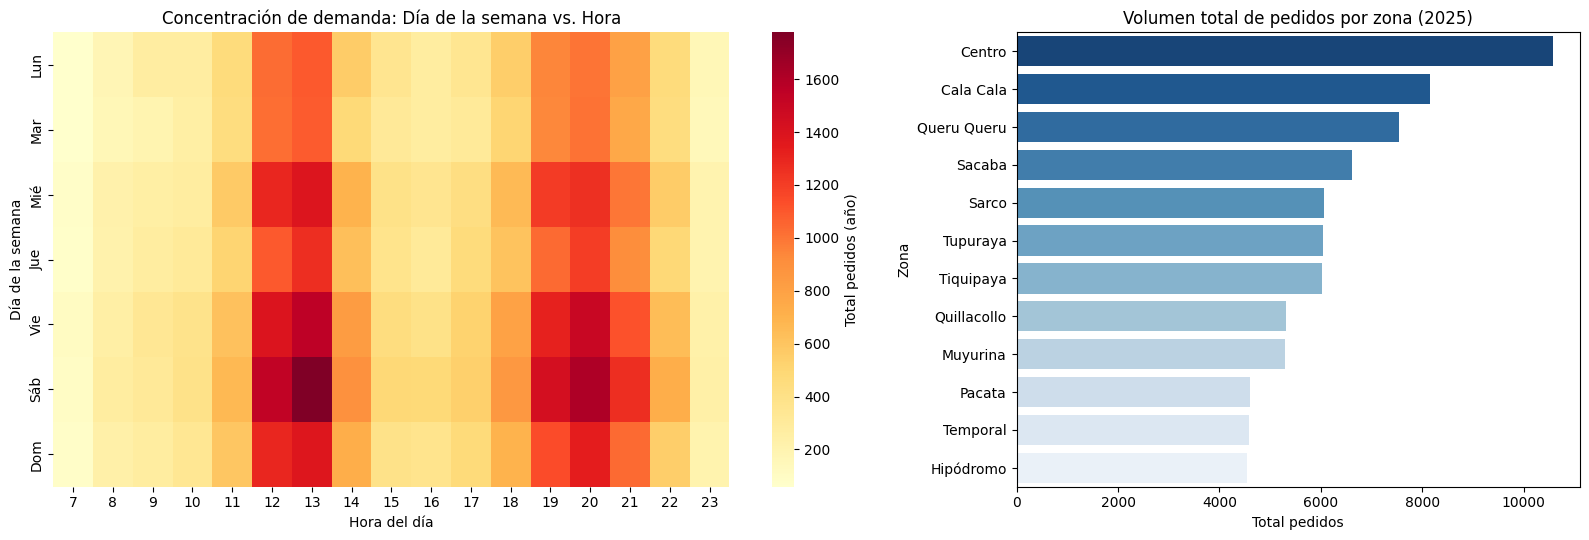

In [5]:
# --- P1: Concentración de demanda (día x hora y zonas) + estimación de riders en hora pico ---
df_dia_hora = con.execute("""
    SELECT
        dia_semana,
        hora,
        COUNT(*) AS total_pedidos,
        COUNT(CASE WHEN estado = 'entregado' THEN 1 END) AS pedidos_entregados,
        COUNT(DISTINCT rider_id) FILTER (WHERE rider_asignado) AS riders_activos_unicos,
        ROUND(AVG(tiempo_entrega_min), 1) AS tiempo_prom_min
    FROM oro_pedidos
    GROUP BY 1, 2
    ORDER BY 1, 2
""").df()

df_zonas = con.execute("""
    SELECT
        zona_entrega,
        COUNT(*) AS total_pedidos,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_demanda,
        ROUND(AVG(tiempo_entrega_min), 1) AS tiempo_prom_min,
        COUNT(DISTINCT rider_id) FILTER (WHERE rider_asignado) AS riders_distintos
    FROM oro_pedidos
    WHERE zona_entrega IS NOT NULL
    GROUP BY 1
    ORDER BY total_pedidos DESC
""").df()

# Riders únicos totales en el catálogo / base
total_riders = con.execute("SELECT COUNT(DISTINCT rider_id) FROM plata_riders").fetchone()[0]

# Máximo de pedidos en una hora puntual de todo el año y promedio en la hora pico
pico_hora = con.execute("""
    SELECT
        fecha,
        hora,
        COUNT(*) AS pedidos_en_hora,
        COUNT(DISTINCT rider_id) FILTER (WHERE rider_asignado) AS riders_en_hora
    FROM oro_pedidos
    GROUP BY 1, 2
    ORDER BY pedidos_en_hora DESC
    LIMIT 10
""").df()

print("Top 10 horas más cargadas del año:")
display(pico_hora)

print("\nRanking de zonas por volumen de pedidos:")
display(df_zonas)

# Gráfico: Heatmap día de la semana x hora + ranking de zonas
nombres_dia = {0: "Dom", 1: "Lun", 2: "Mar", 3: "Mié", 4: "Jue", 5: "Vie", 6: "Sáb"}
df_dia_hora["dia_nombre"] = df_dia_hora["dia_semana"].map(nombres_dia)
orden_dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

pivote = df_dia_hora.pivot(index="dia_nombre", columns="hora", values="total_pedidos").reindex(orden_dias)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})

sns.heatmap(pivote, annot=False, cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "Total pedidos (año)"})
axes[0].set_title("Concentración de demanda: Día de la semana vs. Hora")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("Día de la semana")

sns.barplot(data=df_zonas, y="zona_entrega", x="total_pedidos", palette="Blues_r", ax=axes[1])
axes[1].set_title("Volumen total de pedidos por zona (2025)")
axes[1].set_xlabel("Total pedidos")
axes[1].set_ylabel("Zona")

plt.tight_layout()
plt.show()

Lo más cargado se junta al mediodía (12–13 h) y hacia las 20:00 —con un tope de 57 pedidos en una hora el 22/02 a las 20:00 (47 riders activos)— y en Centro (14,04%), Cala Cala (10,83%) y Queru Queru (10,01%). Como no supe de entrada si un rider atendía más de un viaje o cubría toda la hora, revisé las 10 horas pico y los tiempos por zona: el apriete mayor está en viajes largos como Quillacollo (39,9 min) y Sacaba (38,3 min) frente a ~21 min cerca del centro.

Resumen diario según día lluvioso (lluvia_mm >= 1.0):


,es_dia_lluvioso,dias,prom_pedidos_dia,prom_entregados_dia,prom_gmv_dia,prom_tiempo_min,prom_calificacion
0,False,284,196.73,188.86,11068.62,22.94,4.182
1,True,81,240.27,223.33,13098.38,31.69,3.845



Métrica: total_pedidos
  No lluvia (n=284): media=196.73, mediana=194.00
  Lluvia    (n=81): media=240.27, mediana=224.00
  Welch t-test: t=6.506, p=0.0000 | Mann-Whitney U: p=0.0000

Métrica: tiempo_entrega_promedio_min
  No lluvia (n=284): media=22.94, mediana=22.80
  Lluvia    (n=81): media=31.69, mediana=31.82
  Welch t-test: t=60.131, p=0.0000 | Mann-Whitney U: p=0.0000

Métrica: calificacion_promedio
  No lluvia (n=284): media=4.18, mediana=4.19
  Lluvia    (n=81): media=3.84, mediana=3.84
  Welch t-test: t=-28.966, p=0.0000 | Mann-Whitney U: p=0.0000


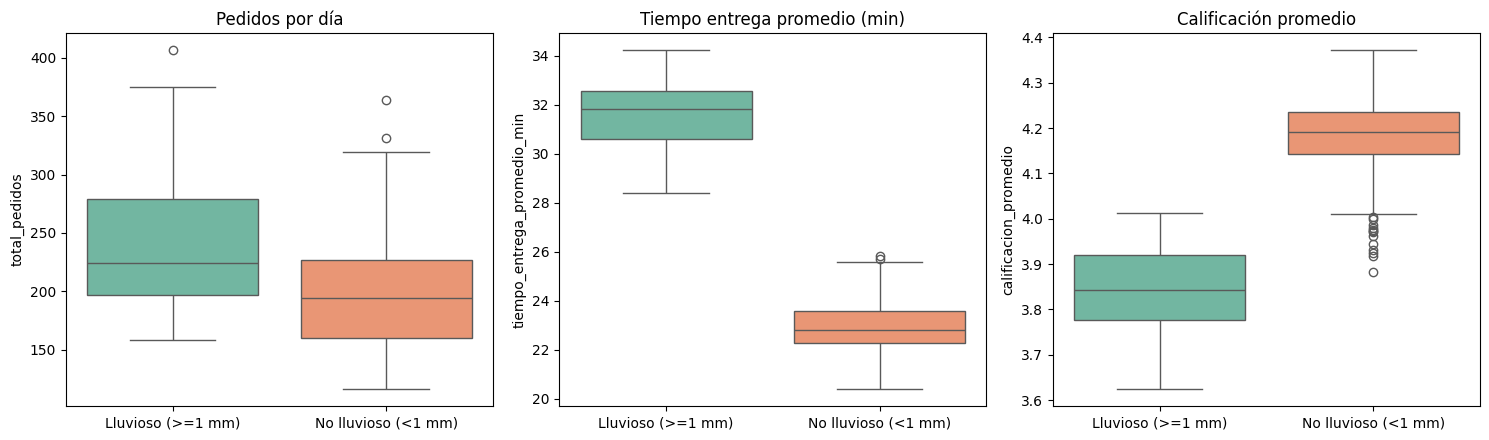

In [7]:
from scipy import stats

# --- P2: Impacto de la lluvia en pedidos, tiempo de entrega y calificación ---
df_lluvia_diario = con.execute("""
    SELECT
        es_dia_lluvioso,
        COUNT(*) AS dias,
        ROUND(AVG(total_pedidos), 2) AS prom_pedidos_dia,
        ROUND(AVG(pedidos_entregados), 2) AS prom_entregados_dia,
        ROUND(AVG(gmv_bs), 2) AS prom_gmv_dia,
        ROUND(AVG(tiempo_entrega_promedio_min), 2) AS prom_tiempo_min,
        ROUND(AVG(calificacion_promedio), 3) AS prom_calificacion
    FROM oro_diario
    GROUP BY es_dia_lluvioso
    ORDER BY es_dia_lluvioso
""").df()

print("Resumen diario según día lluvioso (lluvia_mm >= 1.0):")
display(df_lluvia_diario)

diario_raw = con.execute("""
    SELECT
        es_dia_lluvioso,
        total_pedidos,
        tiempo_entrega_promedio_min,
        calificacion_promedio,
        lluvia_mm
    FROM oro_diario
""").df()

for col in ["total_pedidos", "tiempo_entrega_promedio_min", "calificacion_promedio"]:
    g_no = diario_raw.loc[~diario_raw["es_dia_lluvioso"], col].dropna()
    g_si = diario_raw.loc[diario_raw["es_dia_lluvioso"], col].dropna()
    t_stat, p_val = stats.ttest_ind(g_si, g_no, equal_var=False)
    u_stat, p_u = stats.mannwhitneyu(g_si, g_no, alternative="two-sided")
    print(f"\nMétrica: {col}")
    print(f"  No lluvia (n={len(g_no)}): media={g_no.mean():.2f}, mediana={g_no.median():.2f}")
    print(f"  Lluvia    (n={len(g_si)}): media={g_si.mean():.2f}, mediana={g_si.median():.2f}")
    print(f"  Welch t-test: t={t_stat:.3f}, p={p_val:.4f} | Mann-Whitney U: p={p_u:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
etiquetas = {False: "No lluvioso (<1 mm)", True: "Lluvioso (>=1 mm)"}
diario_raw["tipo_dia"] = diario_raw["es_dia_lluvioso"].map(etiquetas)

sns.boxplot(data=diario_raw, x="tipo_dia", y="total_pedidos", hue="tipo_dia", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Pedidos por día")
axes[0].set_xlabel("")

sns.boxplot(data=diario_raw, x="tipo_dia", y="tiempo_entrega_promedio_min", hue="tipo_dia", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Tiempo entrega promedio (min)")
axes[1].set_xlabel("")

sns.boxplot(data=diario_raw, x="tipo_dia", y="calificacion_promedio", hue="tipo_dia", palette="Set2", legend=False, ax=axes[2])
axes[2].set_title("Calificación promedio")
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

En los 81 días lluviosos (lluvia_mm >= 1.0), el promedio sube de 196,73 a 240,27 pedidos/día y el GMV de Bs 11.068,62 a Bs 13.098,38, pero el tiempo sube de 22,94 a 31,69 min y la calificación baja de 4,182 a 3,845 (p < 0,0001 en Welch t-test y Mann-Whitney U). Para descartar que fuera solo un efecto de medias o estacionalidad anual, contrasté medias y medianas con ambas pruebas y revisé pedidos_entregados y gmv_bs; el dato diario no muestra si llovió justo a la hora pico, pero la caída en rapidez y calificación es clara.

Comparación Miércoles vs. Otros días (Antes vs. Después del 2025-07-02):


,tipo_dia,periodo,dias,prom_pedidos,prom_entregados,prom_gmv,prom_envio_cobrado,prom_ingreso_yallego
0,Miercoles,Post_2Jul,27,245.59,233.07,12079.35,0.00,2322.12
1,Miercoles,Pre_2Jul,26,162.88,155.27,9255.41,1691.55,3470.95
2,Otros_dias,Post_2Jul,156,214.56,205.08,12145.20,2246.09,4589.19
3,Otros_dias,Pre_2Jul,156,198.68,188.47,11173.23,2058.68,4219.14



Detalle a nivel pedido en miércoles (con promo vs sin promo):


,es_promocion_miercoles,total_pedidos_miercoles,prom_pedidos_por_miercoles,prom_costo_envio_pedido,prom_comision_pedido,prom_ingreso_pedido,entregados_envio_cero
0,False,4235,162.88,10.89,11.48,22.35,0.0
1,True,6631,245.59,0.00,10.00,9.96,6293.0


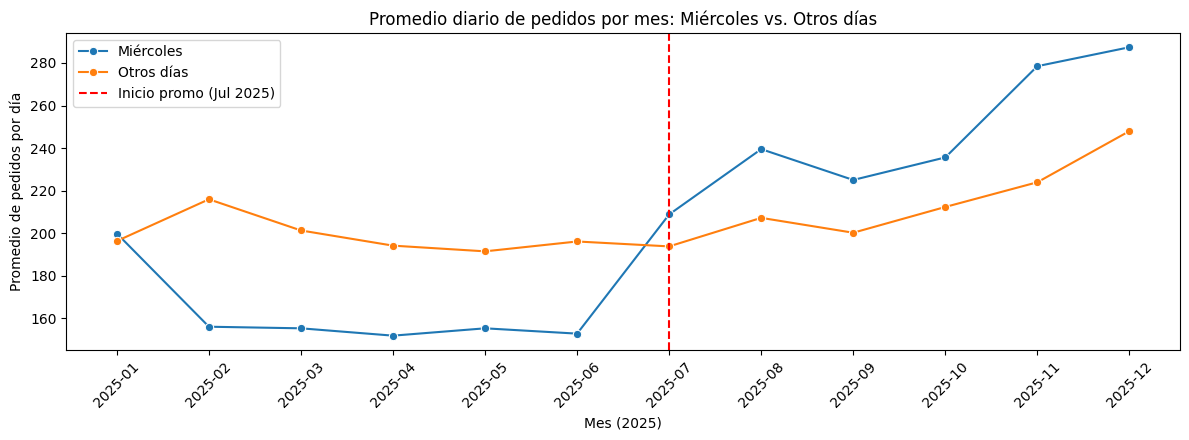

In [10]:
# --- P3: Promoción "Miércoles sin envío" (desde 2025-07-02) ---
df_p3_grupo = con.execute("""
    WITH base_diaria AS (
        SELECT
            fecha,
            CASE WHEN STRFTIME(fecha, '%w') = '3' THEN 'Miercoles' ELSE 'Otros_dias' END AS tipo_dia,
            CASE WHEN fecha >= DATE '2025-07-02' THEN 'Post_2Jul' ELSE 'Pre_2Jul' END AS periodo,
            es_promocion_miercoles,
            total_pedidos,
            pedidos_entregados,
            gmv_bs,
            comision_bs,
            envio_cobrado_bs,
            ingreso_yallego_bs
        FROM oro_diario
    )
    SELECT
        tipo_dia,
        periodo,
        COUNT(*) AS dias,
        ROUND(AVG(total_pedidos), 2) AS prom_pedidos,
        ROUND(AVG(pedidos_entregados), 2) AS prom_entregados,
        ROUND(AVG(gmv_bs), 2) AS prom_gmv,
        ROUND(AVG(envio_cobrado_bs), 2) AS prom_envio_cobrado,
        ROUND(AVG(ingreso_yallego_bs), 2) AS prom_ingreso_yallego
    FROM base_diaria
    GROUP BY 1, 2
    ORDER BY 1, 2
""").df()

print("Comparación Miércoles vs. Otros días (Antes vs. Después del 2025-07-02):")
display(df_p3_grupo)

df_miercoles_detalle = con.execute("""
    SELECT
        es_promocion_miercoles,
        COUNT(*) AS total_pedidos_miercoles,
        ROUND(COUNT(*) * 1.0 / COUNT(DISTINCT fecha), 2) AS prom_pedidos_por_miercoles,
        ROUND(AVG(costo_envio_bs), 2) AS prom_costo_envio_pedido,
        ROUND(AVG(comision_bs), 2) AS prom_comision_pedido,
        ROUND(AVG(ingreso_yallego_bs), 2) AS prom_ingreso_pedido,
        SUM(CASE WHEN costo_envio_bs = 0 AND estado = 'entregado' THEN 1 ELSE 0 END) AS entregados_envio_cero
    FROM oro_pedidos
    WHERE dia_semana = 3
    GROUP BY es_promocion_miercoles
    ORDER BY es_promocion_miercoles
""").df()

print("\nDetalle a nivel pedido en miércoles (con promo vs sin promo):")
display(df_miercoles_detalle)

serie_p3 = con.execute("""
    SELECT
        fecha,
        CASE WHEN STRFTIME(fecha, '%w') = '3' THEN 'Miércoles' ELSE 'Otros días' END AS grupo,
        total_pedidos,
        ingreso_yallego_bs
    FROM oro_diario
""").df()

prom_mensual = (
    serie_p3.assign(mes=pd.to_datetime(serie_p3["fecha"]).dt.to_period("M").astype(str))
    .groupby(["mes", "grupo"], as_index=False)["total_pedidos"].mean()
)

plt.figure(figsize=(12, 4.5))
sns.lineplot(data=prom_mensual, x="mes", y="total_pedidos", hue="grupo", marker="o")
plt.axvline(x="2025-07", color="red", linestyle="--", label="Inicio promo (Jul 2025)")
plt.title("Promedio diario de pedidos por mes: Miércoles vs. Otros días")
plt.xlabel("Mes (2025)")
plt.ylabel("Promedio de pedidos por día")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

Los miércoles suben de 162,88 a 245,59 pedidos/día (+82,71), mientras los demás días suben +15,88 (de 198,68 a 214,56), lo que deja unos +66,8 pedidos/miércoles atribuibles a la promo; a cambio, el ingreso diario de YaLlegó en miércoles pasa de Bs 3.470,95 a Bs 2.322,12 (-Bs 1.148,83/día) y por pedido de Bs 22,35 a Bs 9,96 (6.293 entregados con envío 0). Comparé miércoles y otros días antes y después del 2 de julio y separé volumen, GMV e ingreso para no confundir más pedidos con más caja, sabiendo que aún queda revisar estacionalidad, posible cambio de día de compra y costos operativos.

Calificación según tramo de tiempo de entrega:


,tramo_tiempo,pedidos_entregados,con_calificacion,calif_promedio,tiempo_prom_min
0,1. <= 20 min,26394,19094,4.508,14.3
1,2. 21-35 min,31706,22884,4.063,26.7
2,3. > 35 min,13465,9679,3.382,42.5
3,Sin tiempo,160,112,4.196,NaN



Correlaciones con calificación (Pearson):
calificacion                1.000
tiempo_entrega_min         -0.536
zona_distancia_centro_km   -0.296
monto_bs                   -0.010
propina_bs                  0.079
Name: calificacion, dtype: float64

Zonas ordenadas de menor a mayor calificación:


,zona_entrega,dist_centro_km,tiempo_prom_min,calif_promedio,num_calif
0,Quillacollo,13.5,39.9,3.505,3631
1,Sacaba,12.8,38.3,3.567,4564
2,Tiquipaya,9.2,30.7,3.890,4115
3,Centro,0.0,24.3,4.142,7281
4,Pacata,4.4,21.9,4.216,3154
5,Temporal,4.0,21.3,4.228,3156
6,Muyurina,1.9,21.6,4.229,3662
7,Cala Cala,2.6,20.6,4.262,5545
8,Tupuraya,2.5,21.0,4.267,4145
9,Sarco,2.8,20.8,4.277,4187



5 restaurantes con menor calificación promedio (n >= 50):


,restaurante_nombre,restaurante_tipo_cocina,n_calif,tiempo_prom_min,calif_promedio
0,Don Illimani Café,Café,1393,30.4,3.881
1,Rincón Molle Café,Café,2066,30.1,3.904
2,El Mamá Rosa Sushi,Sushi,1185,30.0,3.904
3,Casa Llajta Comida,Comida típica,445,29.7,3.909
4,Don Tunari Pollo,Pollo,885,30.5,3.931


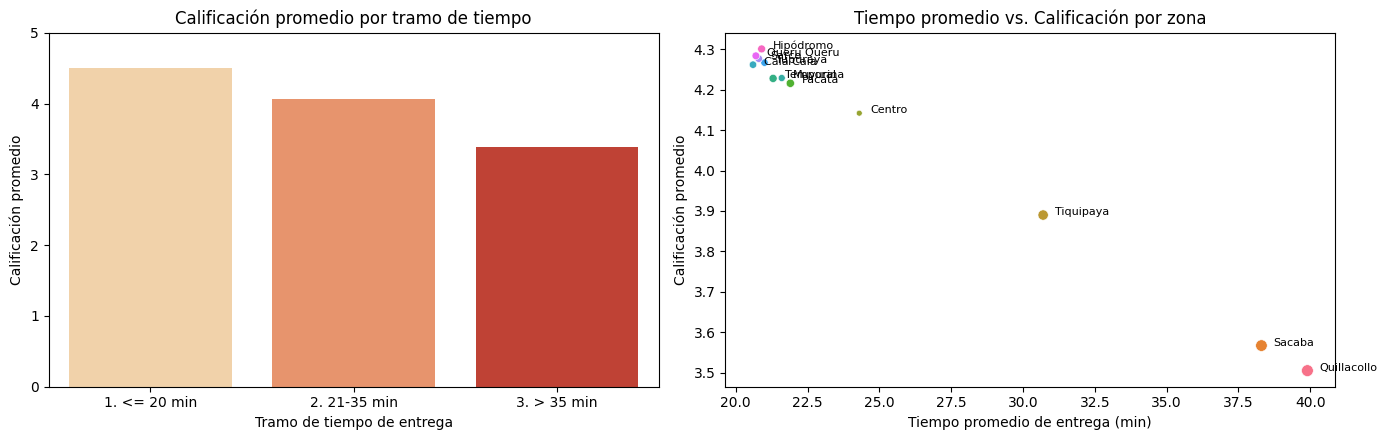

In [11]:
# --- P4: ¿Por qué nos califican mal? (tiempo, zona, restaurante, rider) ---
df_p4_tiempo = con.execute("""
    SELECT
        CASE
            WHEN tiempo_entrega_min IS NULL THEN 'Sin tiempo'
            WHEN tiempo_entrega_min <= 20 THEN '1. <= 20 min'
            WHEN tiempo_entrega_min <= 35 THEN '2. 21-35 min'
            ELSE '3. > 35 min'
        END AS tramo_tiempo,
        COUNT(*) AS pedidos_entregados,
        COUNT(calificacion) AS con_calificacion,
        ROUND(AVG(calificacion), 3) AS calif_promedio,
        ROUND(AVG(tiempo_entrega_min), 1) AS tiempo_prom_min
    FROM oro_pedidos
    WHERE estado = 'entregado'
    GROUP BY 1
    ORDER BY 1
""").df()

print("Calificación según tramo de tiempo de entrega:")
display(df_p4_tiempo)

df_corr = con.execute("""
    SELECT
        calificacion,
        tiempo_entrega_min,
        zona_distancia_centro_km,
        monto_bs,
        propina_bs
    FROM oro_pedidos
    WHERE estado = 'entregado' AND calificacion IS NOT NULL
""").df()

print("\nCorrelaciones con calificación (Pearson):")
print(df_corr.corr()["calificacion"].round(3))

df_p4_zona = con.execute("""
    SELECT
        zona_entrega,
        ROUND(AVG(zona_distancia_centro_km), 1) AS dist_centro_km,
        ROUND(AVG(tiempo_entrega_min), 1) AS tiempo_prom_min,
        ROUND(AVG(calificacion), 3) AS calif_promedio,
        COUNT(calificacion) AS num_calif
    FROM oro_pedidos
    WHERE estado = 'entregado' AND zona_entrega IS NOT NULL
    GROUP BY 1
    ORDER BY calif_promedio ASC
""").df()

print("\nZonas ordenadas de menor a mayor calificación:")
display(df_p4_zona)

# Variación de calificación entre restaurantes y riders (mínimo 50 calificaciones)
df_p4_rest = con.execute("""
    SELECT
        restaurante_nombre,
        restaurante_tipo_cocina,
        COUNT(calificacion) AS n_calif,
        ROUND(AVG(tiempo_entrega_min), 1) AS tiempo_prom_min,
        ROUND(AVG(calificacion), 3) AS calif_promedio
    FROM oro_pedidos
    WHERE estado = 'entregado' AND restaurante_valido AND calificacion IS NOT NULL
    GROUP BY 1, 2
    HAVING COUNT(calificacion) >= 50
    ORDER BY calif_promedio ASC
    LIMIT 5
""").df()

print("\n5 restaurantes con menor calificación promedio (n >= 50):")
display(df_p4_rest)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

tramos_validos = df_p4_tiempo[df_p4_tiempo["tramo_tiempo"] != "Sin tiempo"]
sns.barplot(
    data=tramos_validos, x="tramo_tiempo", y="calif_promedio",
    hue="tramo_tiempo", palette="OrRd", legend=False, ax=axes[0]
)
axes[0].set_title("Calificación promedio por tramo de tiempo")
axes[0].set_xlabel("Tramo de tiempo de entrega")
axes[0].set_ylabel("Calificación promedio")
axes[0].set_ylim(0, 5)

sns.scatterplot(
    data=df_p4_zona, x="tiempo_prom_min", y="calif_promedio",
    size="dist_centro_km", hue="zona_entrega", legend=False, ax=axes[1]
)
for _, r in df_p4_zona.iterrows():
    axes[1].text(r["tiempo_prom_min"] + 0.4, r["calif_promedio"], r["zona_entrega"], fontsize=8)
axes[1].set_title("Tiempo promedio vs. Calificación por zona")
axes[1].set_xlabel("Tiempo promedio de entrega (min)")
axes[1].set_ylabel("Calificación promedio")

plt.tight_layout()
plt.show()

El tiempo de entrega pesa fuerte sobre la nota (r = -0,536): los pedidos en ≤ 20 min promedian 4,508, los de 21–35 min 4,063 y los de > 35 min 3,382 (-1,126 estrellas frente a los más rápidos), golpeando sobre todo a Quillacollo (3,505; 39,9 min; 13,5 km) y Sacaba (3,567; 38,3 min). Revisé tramos de minutos, distancia al centro y locales con al menos 50 calificaciones para ver si el problema era un restaurante específico, y encontré más bien una caída ligada a entregas lentas (sin perder de vista el reescalado de septiembre ni los pedidos sin calificación).

Top 10 restaurantes con mayor tasa de cancelación (mín. 100 pedidos):


,rank_problema,cod_rest,restaurante_nombre,restaurante_tipo_cocina,total_pedidos,entregados,cancelados,tasa_cancelacion_pct,calif_promedio,tiempo_prom_min,gmv_entregado_bs
0,1,R017,Burger Kanata Express,Hamburguesas,2576,2190,386,14.98,3.937,29.3,144574.77
1,2,R016,La Kanata Comida,Comida típica,429,405,24,5.59,4.104,24.4,19579.36
2,3,R028,Don Molle Comida,Comida típica,439,415,24,5.47,4.165,24.2,19159.43
3,4,R025,Sabor Huayllani Pollo,Pollo,450,426,24,5.33,4.137,24.2,26436.13
4,5,R012,Sabor Cristo Hamburguesas,Hamburguesas,2174,2066,108,4.97,4.161,23.7,137335.84
5,6,R027,La Rocha Sushi,Sushi,2791,2653,138,4.94,4.021,27.1,336542.08
6,7,R037,Don Picante Pizza,Pizza,123,117,6,4.88,4.074,24.9,10629.87
7,8,R004,La Sillar Comida,Comida típica,840,799,41,4.88,4.175,23.2,38076.10
8,9,R001,Don Illimani Café,Café,2063,1963,100,4.85,3.881,30.2,70327.95
9,10,R023,Doña Valle Postres,Postres,1654,1574,80,4.84,4.156,23.3,63818.85



Top 10 riders con mayor tasa de cancelación (mín. 100 pedidos):


,rank_problema,rider_id,rider_nombre,rider_vehiculo,total_pedidos,entregados,cancelados,tasa_cancelacion_pct,calif_promedio,tiempo_prom_min,propinas_bs
0,1,RD062,Diego Vargas,moto,635,591,44,6.93,3.968,27.6,1061.4
1,2,RD082,Edwin Gutiérrez,moto,637,596,41,6.44,4.101,24.9,1116.2
2,3,RD034,Ariel Flores,moto,621,581,40,6.44,4.127,23.7,1099.0
3,4,RD036,Marco Fernández,moto,639,598,41,6.42,4.137,23.7,1180.0
4,5,RD012,Marco Choque,bici,622,583,39,6.27,4.119,25.2,1114.2
5,6,RD087,María Villarroel,moto,609,571,38,6.24,4.104,24.9,1025.0
6,7,RD022,Rosa Mercado,moto,610,573,37,6.07,4.168,23.0,1125.0
7,8,RD081,Vania Rojas,bici,629,591,38,6.04,3.985,27.7,1128.6
8,9,RD120,Marco Flores,moto,630,592,38,6.03,4.093,26.0,1292.0
9,10,RD069,Carlos Flores,moto,660,621,39,5.91,4.045,26.0,1207.0


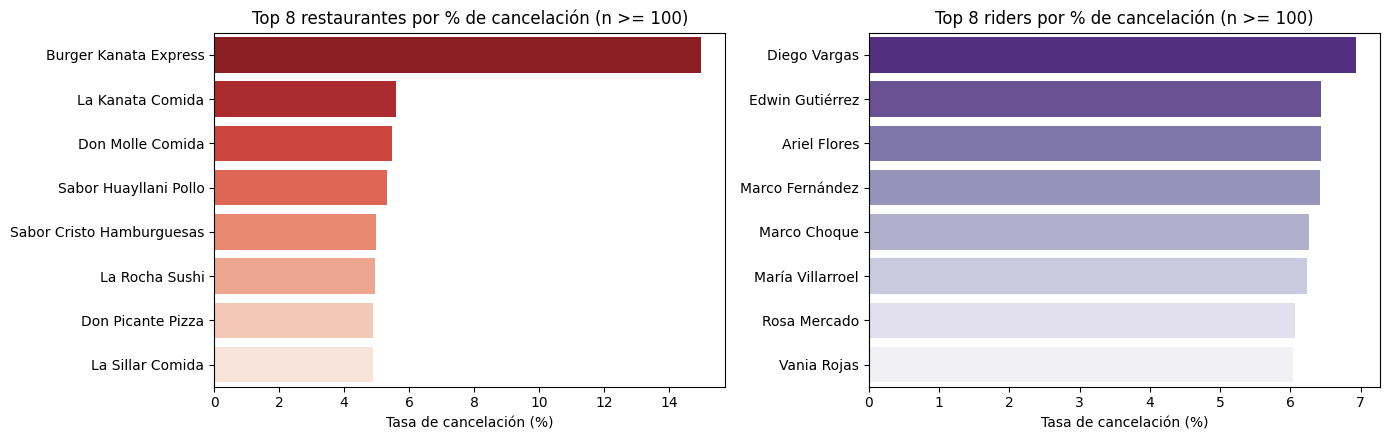

In [13]:
# --- P5: Restaurantes y riders problemáticos (ranking con ROW_NUMBER y cancelaciones) ---
df_p5_rest = con.execute("""
    WITH base_rest AS (
        SELECT
            cod_rest,
            restaurante_nombre,
            restaurante_tipo_cocina,
            COUNT(*) AS total_pedidos,
            COUNT(CASE WHEN estado = 'entregado' THEN 1 END) AS entregados,
            COUNT(CASE WHEN estado = 'cancelado' THEN 1 END) AS cancelados,
            ROUND(COUNT(CASE WHEN estado = 'cancelado' THEN 1 END) * 100.0 / COUNT(*), 2) AS tasa_cancelacion_pct,
            ROUND(AVG(calificacion), 3) AS calif_promedio,
            ROUND(AVG(tiempo_entrega_min), 1) AS tiempo_prom_min,
            ROUND(SUM(CASE WHEN estado = 'entregado' THEN monto_bs ELSE 0 END), 2) AS gmv_entregado_bs
        FROM oro_pedidos
        WHERE restaurante_valido
        GROUP BY 1, 2, 3
        HAVING COUNT(*) >= 100
    )
    SELECT
        ROW_NUMBER() OVER (ORDER BY tasa_cancelacion_pct DESC, calif_promedio ASC) AS rank_problema,
        *
    FROM base_rest
    ORDER BY rank_problema
    LIMIT 10
""").df()

print("Top 10 restaurantes con mayor tasa de cancelación (mín. 100 pedidos):")
display(df_p5_rest)

df_p5_riders = con.execute("""
    WITH base_rider AS (
        SELECT
            rider_id,
            rider_nombre,
            rider_vehiculo,
            COUNT(*) AS total_pedidos,
            COUNT(CASE WHEN estado = 'entregado' THEN 1 END) AS entregados,
            COUNT(CASE WHEN estado = 'cancelado' THEN 1 END) AS cancelados,
            ROUND(COUNT(CASE WHEN estado = 'cancelado' THEN 1 END) * 100.0 / COUNT(*), 2) AS tasa_cancelacion_pct,
            ROUND(AVG(calificacion), 3) AS calif_promedio,
            ROUND(AVG(tiempo_entrega_min), 1) AS tiempo_prom_min,
            ROUND(SUM(CASE WHEN estado = 'entregado' THEN propina_bs ELSE 0 END), 2) AS propinas_bs
        FROM oro_pedidos
        WHERE rider_asignado
        GROUP BY 1, 2, 3
        HAVING COUNT(*) >= 100
    )
    SELECT
        ROW_NUMBER() OVER (ORDER BY tasa_cancelacion_pct DESC, calif_promedio ASC) AS rank_problema,
        *
    FROM base_rider
    ORDER BY rank_problema
    LIMIT 10
""").df()

print("\nTop 10 riders con mayor tasa de cancelación (mín. 100 pedidos):")
display(df_p5_riders)

# Gráfico comparativo de cancelaciones y calificación en top 8 restaurantes
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

top8_rest = df_p5_rest.head(8)
sns.barplot(
    data=top8_rest, y="restaurante_nombre", x="tasa_cancelacion_pct",
    hue="restaurante_nombre", palette="Reds_r", legend=False, ax=axes[0]
)
axes[0].set_title("Top 8 restaurantes por % de cancelación (n >= 100)")
axes[0].set_xlabel("Tasa de cancelación (%)")
axes[0].set_ylabel("")

top8_riders = df_p5_riders.head(8)
sns.barplot(
    data=top8_riders, y="rider_nombre", x="tasa_cancelacion_pct",
    hue="rider_nombre", palette="Purples_r", legend=False, ax=axes[1]
)
axes[1].set_title("Top 8 riders por % de cancelación (n >= 100)")
axes[1].set_xlabel("Tasa de cancelación (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

En restaurantes (mínimo 100 pedidos), Burger Kanata Express (R017) sobresale con 14,98% de cancelación (386 de 2.576; 3,937 de nota; 29,3 min), y Don Illimani Café (R001) suma 4,85% de cancelación, 30,2 min y 3,881 de calificación; en riders, Diego Vargas (RD062) encabeza el listado con 6,93% (44 de 635; 3,968), dentro de un rango estrecho de 5,91% a 6,93%. Exigí al menos 100 pedidos y miré volumen, tiempo y nota junto a la cancelación porque un pedido cancelado o tardío también puede deberse a zona, lluvia o factores fuera del control directo de cada perfil; lo primero que haría es revisar tiempos y cancelaciones con R017 y R001 y ajustar el análisis de riders por zona y clima antes de sancionar.